# Validacion temporal y estabilidad por fuente
Evalua las predicciones guardadas del experimento de modelado sin volver a entrenar y comprueba si la mejora se mantiene por fuente.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / 'data').exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
INPUT = PROJECT_ROOT / 'data' / '04_model_output' / 'modeling' / 'predicciones_prueba.csv'
OUTPUT_DIR = PROJECT_ROOT / 'data' / '04_model_output' / 'validation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
predictions = pd.read_csv(INPUT, parse_dates=['fecha'])
predictions['error_baseline'] = predictions['real'] - predictions['baseline_persistencia']
predictions['error_random_forest'] = predictions['real'] - predictions['random_forest']
predictions['abs_baseline'] = predictions['error_baseline'].abs()
predictions['abs_random_forest'] = predictions['error_random_forest'].abs()
display(predictions.head())

,fuente_original,fecha,real,baseline_persistencia,ridge,random_forest,error_baseline,error_random_forest,abs_baseline,abs_random_forest
0,istanbul_traffic_index,2022-12-23,45.977678,39.550547,47.817062,47.438513,6.427132,-1.460834,6.427132,1.460834
1,istanbul_traffic_index,2022-12-24,61.588905,43.386987,50.628054,64.556153,18.201918,-2.967248,18.201918,2.967248
2,istanbul_traffic_index,2022-12-25,45.594892,45.977678,50.081441,46.724504,-0.382786,-1.129612,0.382786,1.129612
3,istanbul_traffic_index,2022-12-26,38.870007,61.588905,43.930332,40.983607,-22.718899,-2.113600,22.718899,2.113600
4,istanbul_traffic_index,2022-12-27,39.923691,45.594892,42.472185,40.763003,-5.671201,-0.839312,5.671201,0.839312


In [2]:
def metrics_by_source(group):
    return pd.Series({
        'filas_prueba': len(group),
        'mae_baseline': group['abs_baseline'].mean(),
        'mae_random_forest': group['abs_random_forest'].mean(),
        'rmse_baseline': np.sqrt(np.mean(group['error_baseline'] ** 2)),
        'rmse_random_forest': np.sqrt(np.mean(group['error_random_forest'] ** 2)),
        'mejora_mae': group['abs_baseline'].mean() - group['abs_random_forest'].mean(),
    })
by_source = predictions.groupby('fuente_original').apply(metrics_by_source, include_groups=False).reset_index()
by_source['mejora_relativa_pct'] = by_source['mejora_mae'] / by_source['mae_baseline'] * 100
display(by_source)

,fuente_original,filas_prueba,mae_baseline,mae_random_forest,rmse_baseline,rmse_random_forest,mejora_mae,mejora_relativa_pct
0,istanbul_traffic_index,665.0,12.113811,5.370551,16.285460,8.305310,6.743260,55.665883
1,madrid_traffic_points,5.0,0.248895,0.946630,0.306946,0.991827,-0.697736,-280.333651
2,metr_la,23.0,12.689391,10.807494,21.619667,16.364016,1.881897,14.830472
3,pems_bay,35.0,3.112371,0.624970,3.749540,1.081918,2.487401,79.919814
4,sao_paulo_cet,1218.0,1.527293,0.853842,2.036309,1.301546,0.673451,44.094419


In [3]:
rng = np.random.default_rng(42)
improvements = predictions['abs_baseline'].to_numpy() - predictions['abs_random_forest'].to_numpy()
bootstrap_means = np.array([rng.choice(improvements, size=len(improvements), replace=True).mean() for _ in range(2000)])
bootstrap_summary = pd.DataFrame([{'mejora_media_mae': improvements.mean(), 'ic95_inferior': np.quantile(bootstrap_means, 0.025), 'ic95_superior': np.quantile(bootstrap_means, 0.975), 'proporcion_muestras_mejoradas': np.mean(improvements > 0), 'fuentes_con_mejora': int((by_source['mejora_mae'] > 0).sum()), 'fuentes_evaluadas': len(by_source)}])
display(bootstrap_summary)
display(by_source.loc[by_source['mejora_mae'] <= 0, ['fuente_original', 'filas_prueba', 'mejora_mae']])
print('criterio_estabilidad=mixto')

,mejora_media_mae,ic95_inferior,ic95_superior,proporcion_muestras_mejoradas,fuentes_con_mejora,fuentes_evaluadas
0,2.791051,2.481661,3.089033,0.734841,4,5


,fuente_original,filas_prueba,mejora_mae
1,madrid_traffic_points,5.0,-0.697736


criterio_estabilidad=mixto


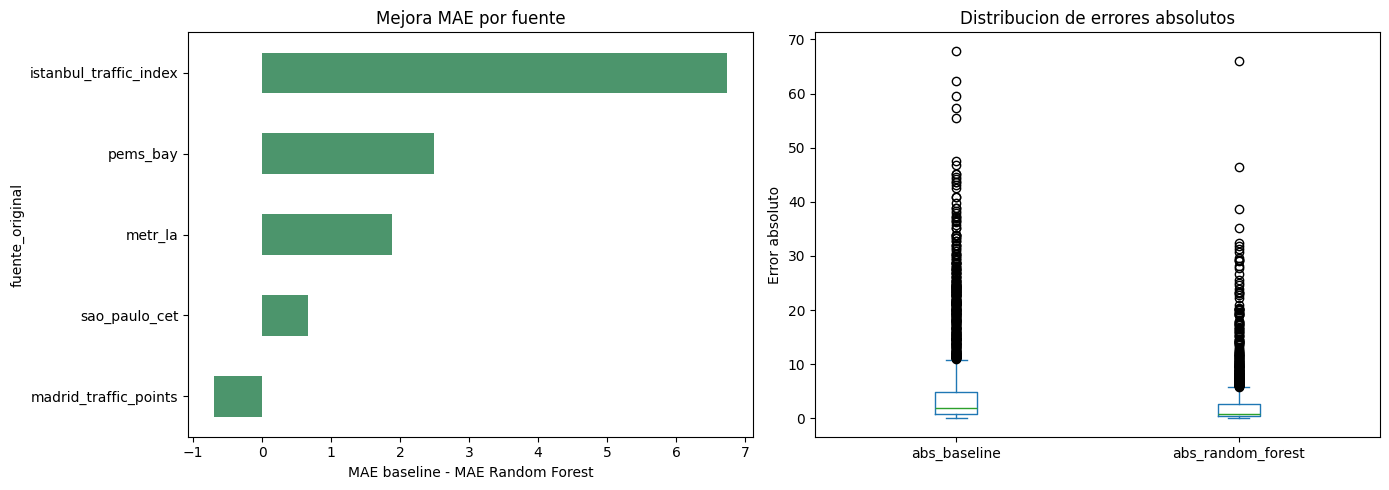

c:\Users\REYES\OneDrive\Desktop\terminado\portafolio data science\TSI\data\04_model_output\validation


In [4]:
by_source.to_csv(OUTPUT_DIR / 'metricas_por_fuente.csv', index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / 'intervalo_bootstrap_mejora.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
by_source.sort_values('mejora_mae').plot.barh(x='fuente_original', y='mejora_mae', ax=axes[0], legend=False, color='#4c956c')
axes[0].set_title('Mejora MAE por fuente')
axes[0].set_xlabel('MAE baseline - MAE Random Forest')
predictions[['abs_baseline', 'abs_random_forest']].plot.box(ax=axes[1])
axes[1].set_title('Distribucion de errores absolutos')
axes[1].set_ylabel('Error absoluto')
plt.tight_layout()
plt.show()
print(OUTPUT_DIR)

## Interpretacion
La validacion mide una tarea de pronostico del TSI provisional. Una mejora estable por fuente no prueba causalidad ni equivale a detectar pre-colapso; ese objetivo requiere una etiqueta operacional y una ventana de anticipacion validada.